In [1]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
import uproot

In [2]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def calc_hist_nonuniform(vals, bins, weights, density=False):
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    for i in range(1, len(bins)):
        hist[i-1] /= (bins[i] - bins[i-1])
        errs[i-1] /= (bins[i] - bins[i-1])       
    if density:
        hist /= weights.sum()
        errs /= weights.sum()   
    return hist, errs, bins

In [5]:
observables = ['evid','xsec','pt','n','parton','q','q2','m','mg','rg','zg','ng'] # q is kappa = 0.5, q2 is kappa = 2

In [6]:
files = ['/nfs/roberts/pi/pi_lbh35/youqi/herwig/herwig_11pthat15_multifold_truth.txt',\
        '/nfs/roberts/pi/pi_lbh35/youqi/herwig/herwig_15pthat20_multifold_truth.txt',\
        '/nfs/roberts/pi/pi_lbh35/youqi/herwig/herwig_20pthat25_multifold_truth.txt',\
        '/nfs/roberts/pi/pi_lbh35/youqi/herwig/herwig_25pthat30_multifold_truth.txt',\
        '/nfs/roberts/pi/pi_lbh35/youqi/herwig/herwig_30pthat35_multifold_truth.txt',\
        '/nfs/roberts/pi/pi_lbh35/youqi/herwig/herwig_35pthat40_multifold_truth.txt',\
        '/nfs/roberts/pi/pi_lbh35/youqi/herwig/herwig_40pthat45_multifold_truth.txt',\
        '/nfs/roberts/pi/pi_lbh35/youqi/herwig/herwig_45pthat50_multifold_truth.txt',\
        '/nfs/roberts/pi/pi_lbh35/youqi/herwig/herwig_50pthat1000_multifold_truth.txt',\
        ]

In [7]:
df_array = []
for i in range(0,len(files)):
    file = files[i]
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/1000000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [8]:
df_hw = df[['pt','q','m','rg','zg','mg','w']]
df_hw.eval('a=(m**2-mg**2)/pt**2', inplace=True)
df_hw['a'].mask(df_hw.a<1e-4, 7.9e-5, inplace=True)
df_hw.eval('loga=log10(a)', inplace=True)

/tmp/tmp.Bl5lQp8xbM/ipykernel_2331546/2277223652.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df_hw['a'].mask(df_hw.a<1e-4, 7.9e-5, inplace=True)
/home/ys668/.conda/envs/rcenv/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs

In [9]:
# Prepare dataframe for PYTHIA6 (nominal) truth
observables2 = ['pt','m','q','rg','zg','mg','w','mcevi']
observabless2 = ['pts','ms','qs','rgs','zgs','mgs']
inputFiles = ['/nfs/roberts/home/ys668/output/run12/all050124_rc_notrueptcons.root']
treeName = ["MatchedTree"]
df_py6 = applyCut(getData(observables2+observabless2, inputFiles[0], treeName[0]), 'pt>0')
df_py6.eval('a=(m**2-mg**2)/pt**2', inplace=True)

In [10]:
df_py6['a'].mask(df_py6.a<1e-4, 7.9e-5, inplace=True)
df_py6.eval('loga=log10(a)', inplace=True)

/tmp/tmp.Bl5lQp8xbM/ipykernel_2331546/817004082.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df_py6['a'].mask(df_py6.a<1e-4, 7.9e-5, inplace=True)
/home/ys668/.conda/envs/rcenv/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*input

In [11]:
np.unique(df_py6['w'])

array([1.13205382e-15, 2.23624237e-14, 1.85923014e-13, 4.02276172e-12,
       1.28765323e-11, 2.08625929e-11, 1.33586558e-10, 3.37211065e-10,
       6.84846047e-09, 4.25489226e-08, 9.55278807e-08, 3.94564864e-07,
       2.49026971e-06])

In [12]:
# set up bins
qedges=np.arange(-1,1.2,0.2)
medges=np.arange(0,13)
rgedges=np.arange(0,0.6,0.1)
zgedges=np.arange(0.1,0.6,0.1)
mgedges=np.arange(0,13)
aedges=np.array([-0.01,0.000001,0.001,0.003,0.005,0.01,0.015,0.02,0.03,0.04,1]) # [-inf, -6, -3, -2.5, -2.3, -2, -1.82, -1.7, -1.5, -1.4, 0]

In [13]:
# Obtain reweight factors from truth ratio of HERWIG/PYTHIA6
df_py6_smallpt = applyCut(df_py6, '20<pt<30')
df_hw_smallpt = applyCut(df_hw, '20<pt<30')
h_py6_smallpt=np.histogramdd([df_py6_smallpt['q'],df_py6_smallpt['m'],df_py6_smallpt['rg'],df_py6_smallpt['zg'],df_py6_smallpt['mg'],df_py6_smallpt['a']], bins=[qedges,medges,rgedges,zgedges,mgedges,aedges], weights=df_py6_smallpt['w'], density=True)[0]
h_hw_smallpt=np.histogramdd([df_hw_smallpt['q'],df_hw_smallpt['m'],df_hw_smallpt['rg'],df_hw_smallpt['zg'],df_hw_smallpt['mg'],df_hw_smallpt['a']], bins=[qedges,medges,rgedges,zgedges,mgedges,aedges], weights=df_hw_smallpt['w'], density=True)[0]
w_smallpt=np.asarray(h_hw_smallpt)/np.asarray(h_py6_smallpt)
w_smallpt[np.isnan(w_smallpt)] = 1
w_smallpt[np.isinf(w_smallpt)] = 1
w_smallpt[w_smallpt>10] = 1 # restrict the spread of relw_new
w_smallpt[w_smallpt<0.1] = 1

df_py6_largept = applyCut(df_py6, '30<pt')
df_hw_largept = applyCut(df_hw, '30<pt')
h_py6_largept=np.histogramdd([df_py6_largept['q'],df_py6_largept['m'],df_py6_largept['rg'],df_py6_largept['zg'],df_py6_largept['mg'],df_py6_largept['a']], bins=[qedges,medges,rgedges,zgedges,mgedges,aedges], weights=df_py6_largept['w'], density=True)[0]
h_hw_largept=np.histogramdd([df_hw_largept['q'],df_hw_largept['m'],df_hw_largept['rg'],df_hw_largept['zg'],df_hw_largept['mg'],df_hw_largept['a']], bins=[qedges,medges,rgedges,zgedges,mgedges,aedges], weights=df_hw_largept['w'], density=True)[0]
w_largept=np.asarray(h_hw_largept)/np.asarray(h_py6_largept)
w_largept[np.isnan(w_largept)] = 1
w_largept[np.isinf(w_largept)] = 1
w_largept[w_largept>10] = 1
w_largept[w_largept<0.1] = 1

/tmp/tmp.Bl5lQp8xbM/ipykernel_2331546/3368798076.py:6: RuntimeWarning: divide by zero encountered in divide
  w_smallpt=np.asarray(h_hw_smallpt)/np.asarray(h_py6_smallpt)
/tmp/tmp.Bl5lQp8xbM/ipykernel_2331546/3368798076.py:6: RuntimeWarning: invalid value encountered in divide
  w_smallpt=np.asarray(h_hw_smallpt)/np.asarray(h_py6_smallpt)
/tmp/tmp.Bl5lQp8xbM/ipykernel_2331546/3368798076.py:16: RuntimeWarning: divide by zero encountered in divide
  w_largept=np.asarray(h_hw_largept)/np.asarray(h_py6_largept)
/tmp/tmp.Bl5lQp8xbM/ipykernel_2331546/3368798076.py:16: RuntimeWarning: invalid value encountered in divide
  w_largept=np.asarray(h_hw_largept)/np.asarray(h_py6_largept)


In [15]:
# Prepare dataframe for PYTHIA6+embedding matched jets
observables2 = ['pt','m','q','rg','zg','mg','w','mcevi']
observabless2 = ['pts','ms','qs','rgs','zgs','mgs']
inputFiles = ['/nfs/roberts/home/ys668/output/run12/all050124_rc_notrueptcons.root']
treeName = ["MatchedTree"]
df1 = applyCut(getData(observables2+observabless2, inputFiles[0], treeName[0]), 'pt>0 and pts>0 and w<5e-9')
df1.eval('a=(m**2-mg**2)/pt**2', inplace=True)

In [16]:
df1.shape[0]

4169989

In [17]:
digits_q = np.digitize(df1['q'], qedges)
digits_m = np.digitize(df1['m'], medges)
digits_rg = np.digitize(df1['rg'], rgedges)
digits_zg = np.digitize(df1['zg'], zgedges)
digits_mg = np.digitize(df1['mg'], mgedges)
digits_a = np.digitize(df1['a'], aedges)

In [18]:
# Reweight matched PYTHIA6+embedding by truth ratio of HERWIG/PYTHIA6
w_tot=[]
for i in range(0,df1.shape[0]): # loop over each jet in embedding
    if ( df1.iloc[i]['pt'] < 20 or df1.iloc[i]['m'] > 12 or df1.iloc[i]['q'] < -1 or df1.iloc[i]['q'] > 1 or df1.iloc[i]['rg'] < 0 or df1.iloc[i]['rg'] > 0.4 or df1.iloc[i]['mg'] > 12 ):
        w_tot.append(df1.iloc[i]['w'])
    elif ( df1.iloc[i]['pt'] < 30):
        w_tot.append(df1.iloc[i]['w']*w_smallpt[digits_q[i]-1][digits_m[i]-1][digits_rg[i]-1][digits_zg[i]-1][digits_mg[i]-1][digits_a[i]-1])
    else:
        w_tot.append(df1.iloc[i]['w']*w_largept[digits_q[i]-1][digits_m[i]-1][digits_rg[i]-1][digits_zg[i]-1][digits_mg[i]-1][digits_a[i]-1])
df1['relw_new'] = np.asarray(w_tot)/max(w_tot)

# Compare all truth distributions before reweighting

In [19]:
ob_array = ['q','m','mg','rg','zg','loga']
ob_label_array = ['$Q$','$M$ [GeV]','$M_g$ [GeV]', '$R_g$','$z_g$','$\log(a)$']
logaedges = np.array([-4.2,-4.1,-4,-2.5, -2.25, -2.125, -2., -1.875, -1.625, 0])
binedges_array = [qedges,medges,mgedges,rgedges,zgedges,logaedges]

<>:2: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:2: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
/tmp/tmp.Bl5lQp8xbM/ipykernel_2331546/128419451.py:2: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  ob_label_array = ['$Q$','$M$ [GeV]','$M_g$ [GeV]', '$R_g$','$z_g$','$\log(a)$']


In [21]:
cut = '20<pt<30'
df_hw_cut = applyCut(df_hw, cut)
df_py_cut = applyCut(df_py6, cut)


observable: q , cut: 20<pt<30


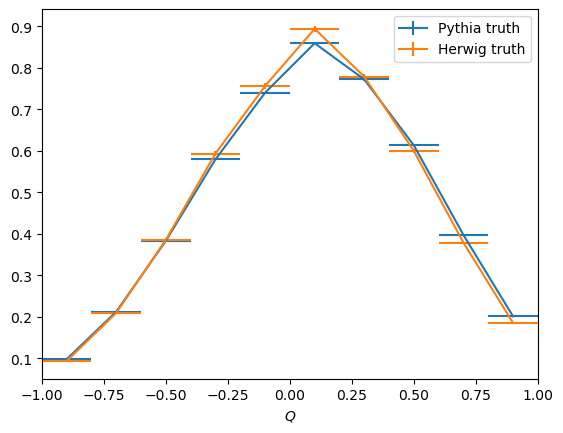


observable: m , cut: 20<pt<30


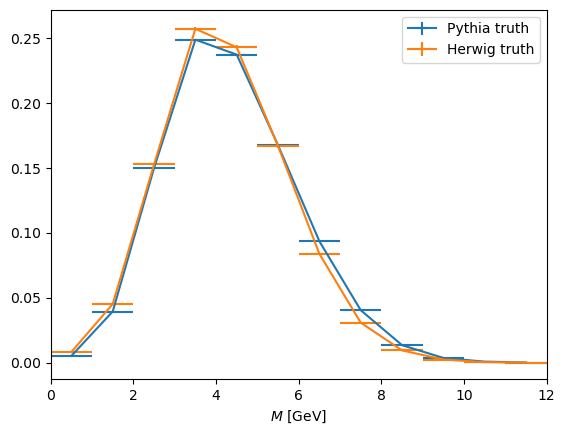


observable: mg , cut: 20<pt<30


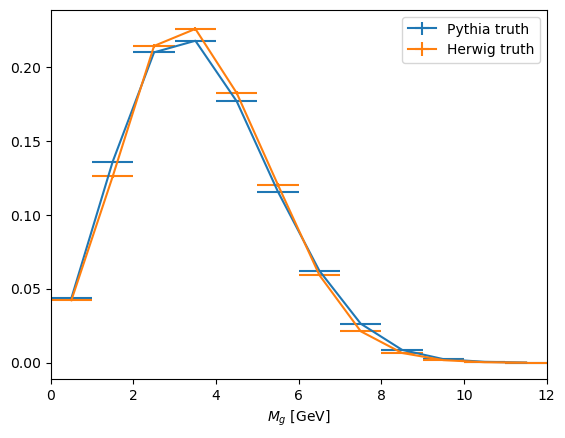


observable: rg , cut: 20<pt<30


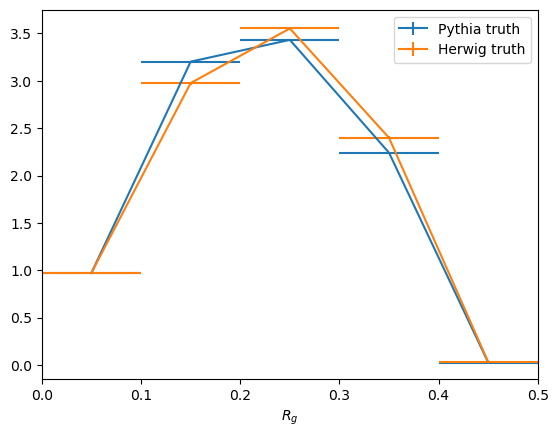


observable: zg , cut: 20<pt<30


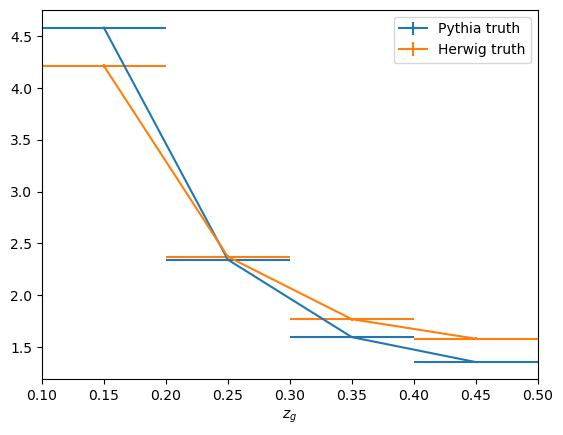


observable: loga , cut: 20<pt<30


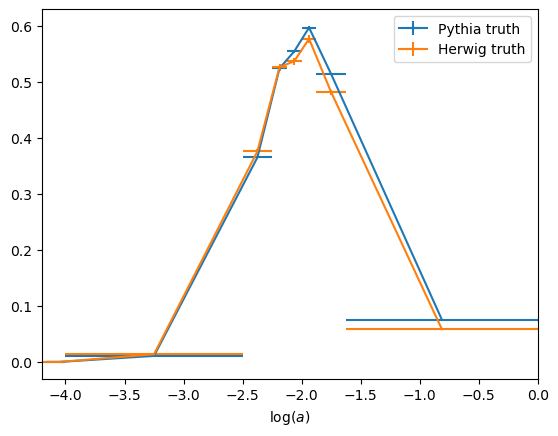

In [22]:
for i in range(0, len(ob_array)):
    ob = ob_array[i]
    binedges = binedges_array[i]

    print('\nobservable:', ob, ', cut:', cut)
    x = []
    for j in range(0, len(binedges)-1):
        midpoint = 0.5 * (binedges[j] + binedges[j+1])
        x.append(midpoint)
    y_py, err_py = calc_hist_nonuniform(df_py_cut[ob], bins=binedges, weights=df_py_cut['w'], density=True)[:2]
    y_hw, err_hw = calc_hist_nonuniform(df_hw_cut[ob], bins=binedges, weights=df_hw_cut['w'], density=True)[:2]
    
    plt.cla()
    plt.errorbar(x, y_py, xerr=binedges[1:]-x, yerr=err_py, label='Pythia truth')
    plt.errorbar(x, y_hw, xerr=binedges[1:]-x, yerr=err_hw, label='Herwig truth')
    plt.xlabel(ob_label_array[i])
    plt.xlim(binedges[0], binedges[-1])
    if (ob=='rg'):
        plt.xlim(left=0)
    elif (ob=='zg'):
        plt.xlim(left=0.1)
    #elif (ob=='a'):
    #    plt.xscale('log')
    plt.legend()
    plt.show()

# Compare matched distributions after reweighting

In [23]:
df1['a'].mask(df1.a<1e-4, 7.9e-5, inplace=True)
df1.eval('loga=log10(a)', inplace=True)

/tmp/tmp.Bl5lQp8xbM/ipykernel_2331546/3430972638.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df1['a'].mask(df1.a<1e-4, 7.9e-5, inplace=True)
/home/ys668/.conda/envs/rcenv/lib/python3.14/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **

In [24]:
cut = '20<pt<30'
df1_cut = applyCut(df1, cut)


observable: q , cut: 20<pt<30
reweighted MC effective counts: [6182.39639548042, 13820.035913476086, 24590.964204163025, 38695.41453019819, 50396.343905604204, 55445.42006787044, 52196.37438208016, 41546.256892329824, 26242.272731224475, 13298.221191921311]


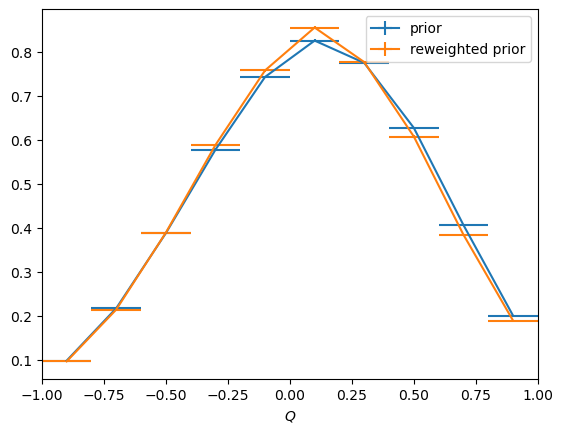


observable: m , cut: 20<pt<30
reweighted MC effective counts: [1119.109206304768, 12186.551631766297, 52016.11233448639, 82863.88731641692, 80969.1909981888, 55381.747590062536, 31536.390560704873, 14474.706671399214, 4625.578333827339, 1566.6490527211877, 476.30263406552666, 57.27407560666697]


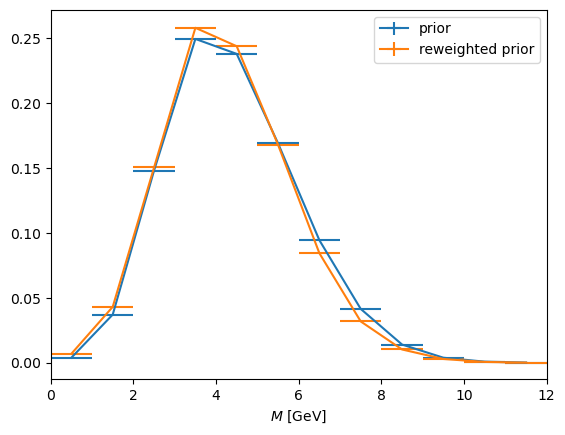


observable: mg , cut: 20<pt<30
reweighted MC effective counts: [12114.377904969995, 46468.554852421454, 72814.84887635475, 70428.6237394437, 59831.791741030596, 38516.73324256737, 21212.190827111463, 9856.245554067036, 3114.220744600352, 947.9382606249573, 302.79970947464, 67.72336022296685]


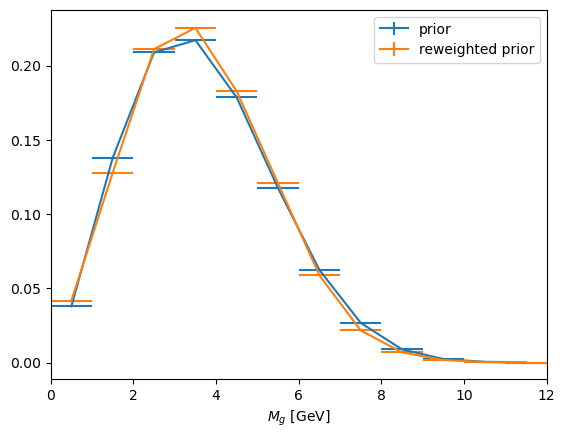


observable: rg , cut: 20<pt<30
reweighted MC effective counts: [29548.26864022701, 114002.60112897641, 115314.7421421075, 73473.61780582657, 609.8430273463779]


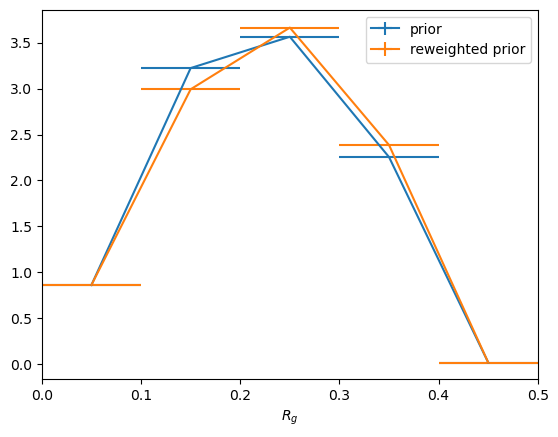


observable: zg , cut: 20<pt<30
reweighted MC effective counts: [160461.97983077512, 78660.13053794662, 52407.97635820263, 43328.739467259096]


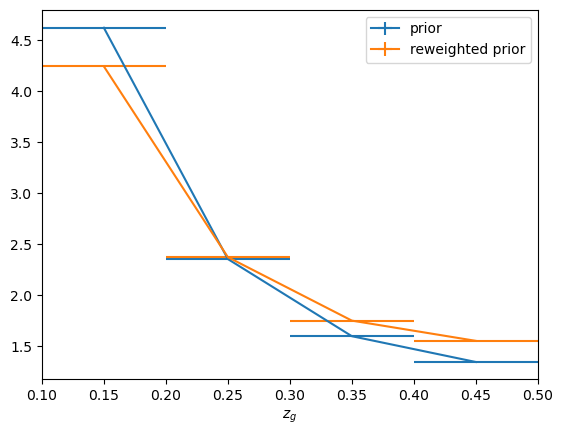


observable: loga , cut: 20<pt<30
reweighted MC effective counts: [1.153364576721551, 0.0, 6537.493834938302, 31956.389384884675, 23363.96738645773, 25821.04884428525, 25318.470848253684, 42975.8700562283, 33984.31370440944]


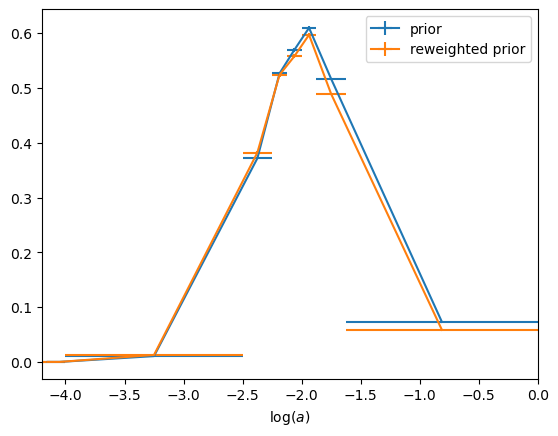

In [25]:
for i in range(0, len(ob_array)):
    ob = ob_array[i]
    binedges = binedges_array[i]

    print('\nobservable:', ob, ', cut:', cut)
    x = []
    for j in range(0, len(binedges)-1):
        midpoint = 0.5 * (binedges[j] + binedges[j+1])
        x.append(midpoint)
    y_prior, err_prior = calc_hist_nonuniform(df1_cut[ob], bins=binedges, weights=df1_cut['relw_new'], density=True)[:2]
    y_old_prior, err_old_prior = calc_hist_nonuniform(df1_cut[ob], bins=binedges, weights=df1_cut['w'], density=True)[:2]
    neff_array = []
    for j in range(0, len(binedges)-1):
        neff = sum(df1_cut[(df1_cut[ob]>binedges[j]) & (df1_cut[ob]<binedges[j+1])]['relw_new'])**2 / (1e-50+sum(df1_cut[(df1_cut[ob]>binedges[j]) & (df1_cut[ob]<binedges[j+1])]['relw_new']**2))
        neff_array.append(neff)
    print("reweighted MC effective counts:", neff_array)
    
    plt.cla()
    plt.errorbar(x, y_old_prior, xerr=binedges[1:]-x, yerr=err_old_prior, label='prior')
    plt.errorbar(x, y_prior, xerr=binedges[1:]-x, yerr=err_prior, label='reweighted prior')
    plt.xlabel(ob_label_array[i])
    plt.xlim(binedges[0], binedges[-1])
    if (ob=='rg'):
        plt.xlim(left=0)
    elif (ob=='zg'):
        plt.xlim(left=0.1)
    #elif (ob=='a'):
    #    plt.xscale('log')
    plt.legend()
    plt.show()

In [26]:
cut = '30<pt<50'
df1_cut = applyCut(df1, cut)


observable: q , cut: 30<pt<50
reweighted MC effective counts: [1805.4611334040824, 3449.672367554438, 6900.000939422593, 12864.331400939991, 16764.66017081384, 20378.216521771563, 19870.940286809906, 15595.373628918474, 9406.437480548533, 4027.408386363195]


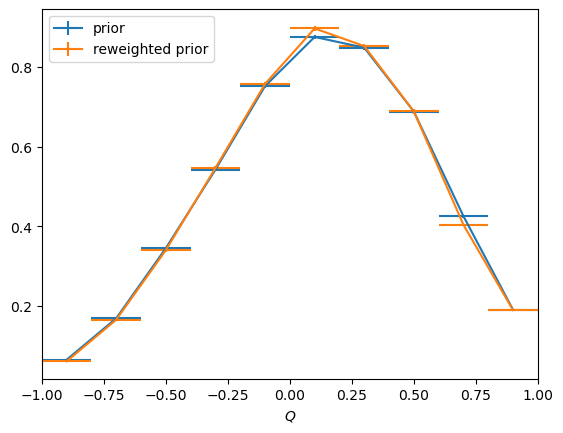


observable: m , cut: 30<pt<50
reweighted MC effective counts: [151.46157827551426, 1535.5068081474506, 7892.609634763548, 17859.593266586904, 23461.997630510956, 22480.548164224314, 17397.333873116677, 10651.605108770374, 6814.337201527633, 3912.398301274223, 1580.2513819225508, 678.5273741962537]


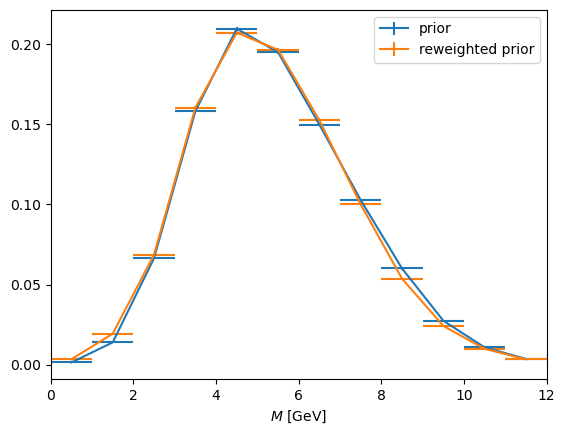


observable: mg , cut: 30<pt<50
reweighted MC effective counts: [3615.9991321719094, 14678.797788547534, 22433.225576086264, 20385.965169072966, 16874.715111222267, 13884.297992343283, 9106.627075995242, 5967.414938961503, 3707.7741163321225, 2107.243274493524, 860.1064170557229, 384.26083137716915]


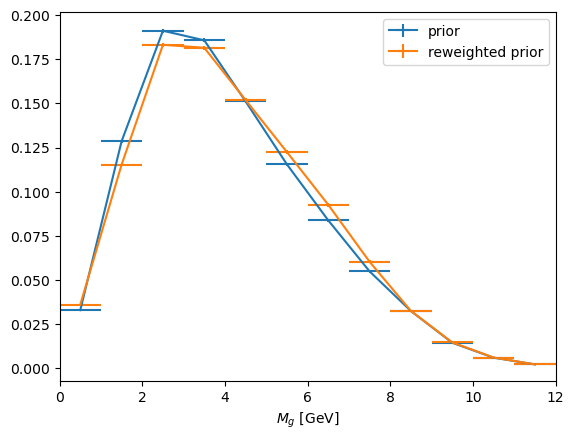


observable: rg , cut: 30<pt<50
reweighted MC effective counts: [23291.51737330758, 47260.56868303135, 30624.62227823719, 12814.641119529837, 159.09027700054776]


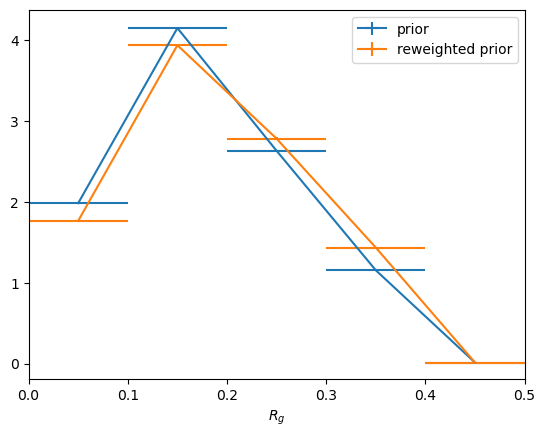


observable: zg , cut: 30<pt<50
reweighted MC effective counts: [58631.691414578534, 24999.464304347486, 16428.191815842958, 13938.289290632112]


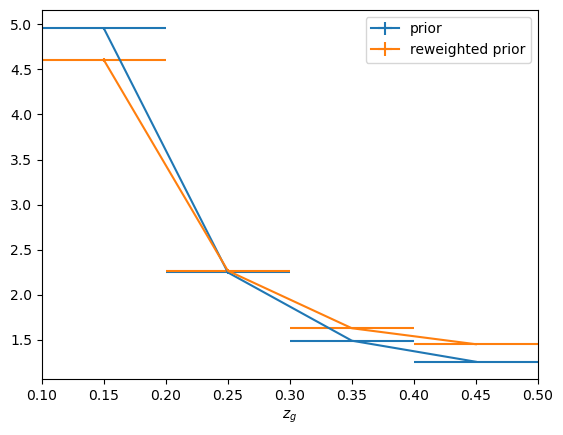


observable: loga , cut: 30<pt<50
reweighted MC effective counts: [1.0, 1.0, 8079.405362966389, 14433.856786664697, 9406.200386280294, 10770.936916722487, 11516.343755936772, 17859.4478103663, 11856.557000329827]


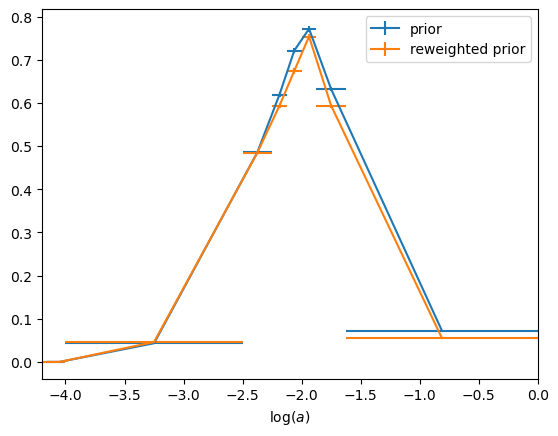

In [27]:
for i in range(0, len(ob_array)):
    ob = ob_array[i]
    binedges = binedges_array[i]

    print('\nobservable:', ob, ', cut:', cut)
    x = []
    for j in range(0, len(binedges)-1):
        midpoint = 0.5 * (binedges[j] + binedges[j+1])
        x.append(midpoint)
    y_prior, err_prior = calc_hist_nonuniform(df1_cut[ob], bins=binedges, weights=df1_cut['relw_new'], density=True)[:2]
    y_old_prior, err_old_prior = calc_hist_nonuniform(df1_cut[ob], bins=binedges, weights=df1_cut['w'], density=True)[:2]
    neff_array = []
    for j in range(0, len(binedges)-1):
        neff = sum(df1_cut[(df1_cut[ob]>binedges[j]) & (df1_cut[ob]<binedges[j+1])]['relw_new'])**2 / (1e-50+sum(df1_cut[(df1_cut[ob]>binedges[j]) & (df1_cut[ob]<binedges[j+1])]['relw_new']**2))
        neff_array.append(neff)
    print("reweighted MC effective counts:", neff_array)
    
    plt.cla()
    plt.errorbar(x, y_old_prior, xerr=binedges[1:]-x, yerr=err_old_prior, label='prior')
    plt.errorbar(x, y_prior, xerr=binedges[1:]-x, yerr=err_prior, label='reweighted prior')
    plt.xlabel(ob_label_array[i])
    plt.xlim(binedges[0], binedges[-1])
    if (ob=='rg'):
        plt.xlim(left=0)
    elif (ob=='zg'):
        plt.xlim(left=0.1)
    #elif (ob=='a'):
    #    plt.xscale('log')
    plt.legend()
    plt.show()

In [28]:
ob_array = ['qs','ms','mgs','rgs','zgs']
ob_label_array = ['detector level $Q$','detector level $M$ [GeV]','detector level $M_g$ [GeV]', 'detector level $R_g$','detector level $z_g$']
binedges_array = [qedges,medges,mgedges,rgedges,zgedges]

In [29]:
cut = '20<pts<30'
df1_cut = applyCut(df1, cut)


observable: qs , cut: 20<pts<30
reweighted MC effective counts: [6361.842305356961, 10759.107818784507, 17654.435093920794, 24618.896383031664, 30897.549924634146, 33592.76555014682, 32236.002957184653, 27704.666605763126, 19281.509282711908, 11477.101467553946]


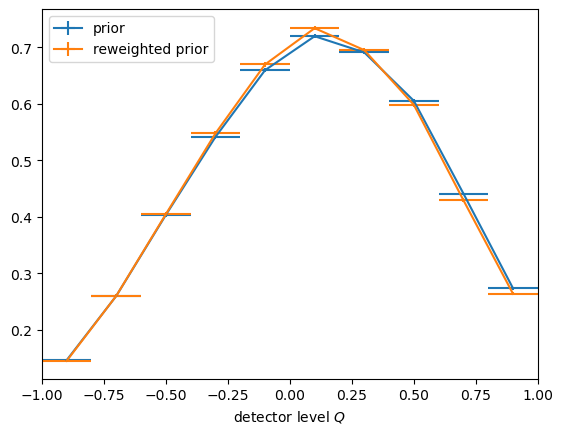


observable: ms , cut: 20<pts<30
reweighted MC effective counts: [1706.4208160629012, 21589.673578812588, 74494.69813732561, 82563.84288547398, 38640.347759497745, 9545.389967300975, 1846.2463148973484, 112.58183676029263, 4.832356457375198, 0.0, 0.0, 0.0]


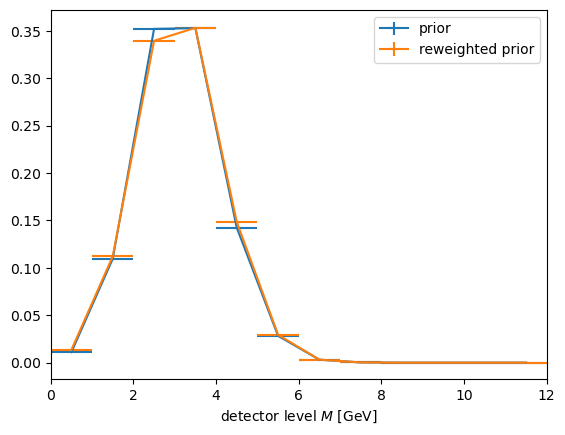


observable: mgs , cut: 20<pts<30
reweighted MC effective counts: [17831.504968466343, 57850.75048875716, 65763.69261473019, 51075.39423735044, 26710.942041278213, 7555.4669811989, 1591.9869058608522, 102.07801111474856, 4.612029484276879, 0.0, 0.0, 0.0]


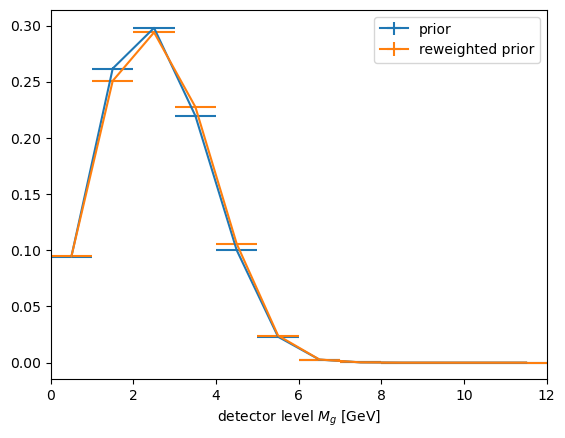


observable: rgs , cut: 20<pts<30
reweighted MC effective counts: [23791.911435883783, 80347.65279935705, 73775.4761030162, 45497.47158204066, 613.0748869936104]


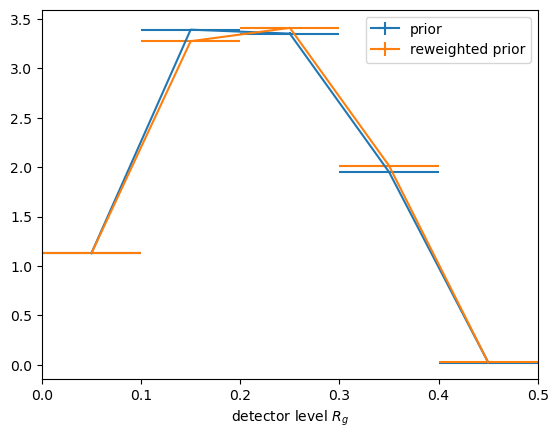


observable: zgs , cut: 20<pts<30
reweighted MC effective counts: [101767.62324736275, 53478.15584947469, 37428.40322699163, 30961.502097307944]


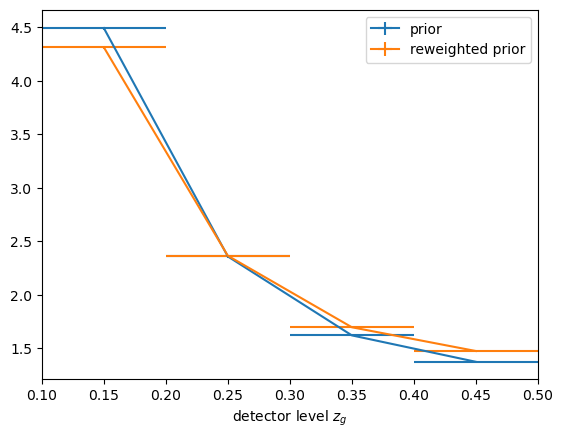

In [30]:
for i in range(0, len(ob_array)):
    ob = ob_array[i]
    binedges = binedges_array[i]

    print('\nobservable:', ob, ', cut:', cut)
    x = []
    for j in range(0, len(binedges)-1):
        midpoint = 0.5 * (binedges[j] + binedges[j+1])
        x.append(midpoint)
    y_prior, err_prior = calc_hist_nonuniform(df1_cut[ob], bins=binedges, weights=df1_cut['relw_new'], density=True)[:2]
    y_old_prior, err_old_prior = calc_hist_nonuniform(df1_cut[ob], bins=binedges, weights=df1_cut['w'], density=True)[:2]
    neff_array = []
    for j in range(0, len(binedges)-1):
        neff = sum(df1_cut[(df1_cut[ob]>binedges[j]) & (df1_cut[ob]<binedges[j+1])]['relw_new'])**2 / (1e-50+sum(df1_cut[(df1_cut[ob]>binedges[j]) & (df1_cut[ob]<binedges[j+1])]['relw_new']**2))
        neff_array.append(neff)
    print("reweighted MC effective counts:", neff_array)
    
    plt.cla()
    plt.errorbar(x, y_old_prior, xerr=binedges[1:]-x, yerr=err_old_prior, label='prior')
    plt.errorbar(x, y_prior, xerr=binedges[1:]-x, yerr=err_prior, label='reweighted prior')
    plt.xlabel(ob_label_array[i])
    plt.xlim(binedges[0], binedges[-1])
    if (ob=='rg'):
        plt.xlim(left=0)
    elif (ob=='zg'):
        plt.xlim(left=0.1)
    #elif (ob=='a'):
    #    plt.xscale('log')
    plt.legend()
    plt.show()

In [31]:
cut = '30<pts<50'
df1_cut = applyCut(df1, cut)


observable: qs , cut: 30<pts<50
reweighted MC effective counts: [958.3184338900297, 2379.172024479753, 3701.7378691916806, 6073.50682197337, 7693.979337997855, 9215.86683335007, 9168.74561390849, 7481.982572386374, 5265.898915551301, 3036.35455119724]


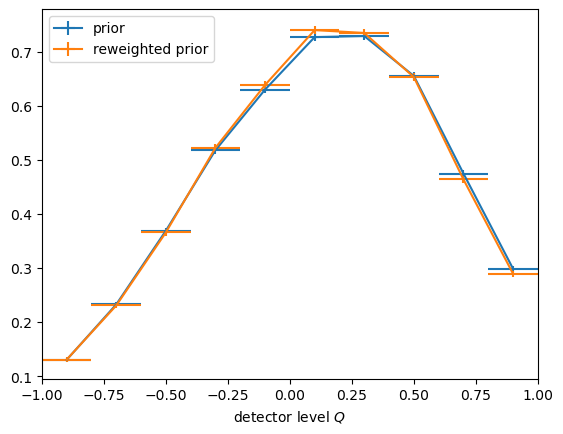


observable: ms , cut: 30<pts<50
reweighted MC effective counts: [155.08133086957955, 2168.8994684749737, 9684.91319600829, 18345.566935305083, 15226.355511105568, 7813.49296140636, 3499.5371951001634, 937.3330710486013, 429.0341542100777, 53.76606251585221, 17.76789083072196, 60.363975934349625]


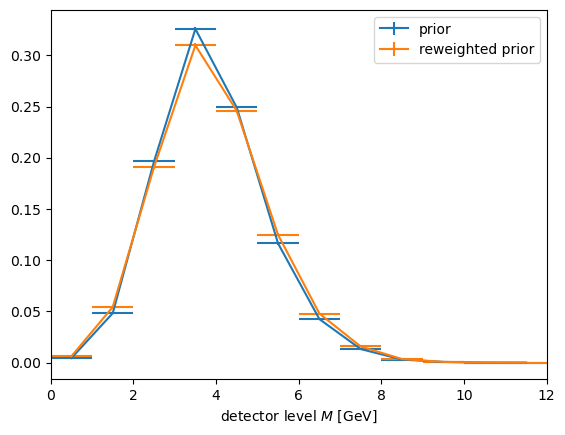


observable: mgs , cut: 30<pts<50
reweighted MC effective counts: [4004.596824952591, 12926.26682321659, 15597.080521239657, 10383.0103470713, 7468.573899932457, 3974.7608257039205, 2299.794863868694, 693.0501953626593, 365.38108059895944, 45.31870218729683, 15.467382064613176, 57.137971138136365]


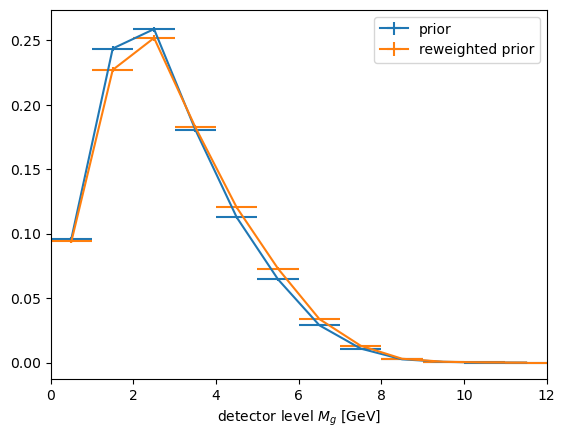


observable: rgs , cut: 30<pts<50
reweighted MC effective counts: [11904.829273185798, 25182.470037795574, 13793.499282454848, 5844.107345070554, 66.59269157309826]


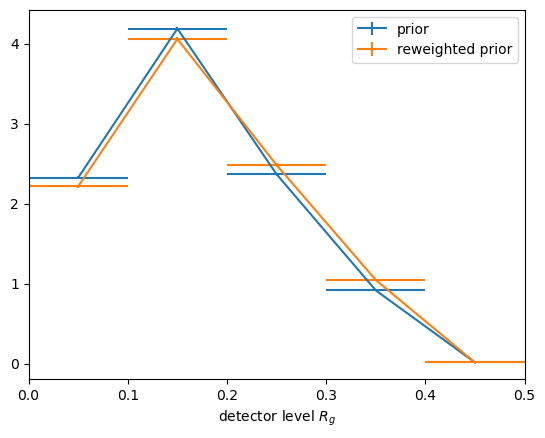


observable: zgs , cut: 30<pts<50
reweighted MC effective counts: [28098.98711454775, 12852.907257807383, 8480.592495397075, 7269.968182399924]


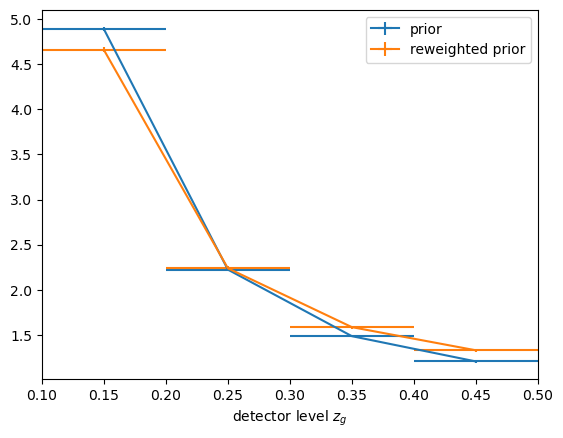

In [32]:
for i in range(0, len(ob_array)):
    ob = ob_array[i]
    binedges = binedges_array[i]

    print('\nobservable:', ob, ', cut:', cut)
    x = []
    for j in range(0, len(binedges)-1):
        midpoint = 0.5 * (binedges[j] + binedges[j+1])
        x.append(midpoint)
    y_prior, err_prior = calc_hist_nonuniform(df1_cut[ob], bins=binedges, weights=df1_cut['relw_new'], density=True)[:2]
    y_old_prior, err_old_prior = calc_hist_nonuniform(df1_cut[ob], bins=binedges, weights=df1_cut['w'], density=True)[:2]
    neff_array = []
    for j in range(0, len(binedges)-1):
        neff = sum(df1_cut[(df1_cut[ob]>binedges[j]) & (df1_cut[ob]<binedges[j+1])]['relw_new'])**2 / (1e-50+sum(df1_cut[(df1_cut[ob]>binedges[j]) & (df1_cut[ob]<binedges[j+1])]['relw_new']**2))
        neff_array.append(neff)
    print("reweighted MC effective counts:", neff_array)
    
    plt.cla()
    plt.errorbar(x, y_old_prior, xerr=binedges[1:]-x, yerr=err_old_prior, label='prior')
    plt.errorbar(x, y_prior, xerr=binedges[1:]-x, yerr=err_prior, label='reweighted prior')
    plt.xlabel(ob_label_array[i])
    plt.xlim(binedges[0], binedges[-1])
    if (ob=='rg'):
        plt.xlim(left=0)
    elif (ob=='zg'):
        plt.xlim(left=0.1)
    #elif (ob=='a'):
    #    plt.xscale('log')
    plt.legend()
    plt.show()

In [33]:
ob = 'pt'
binedges = np.array([5., 10., 15., 20., 25., 30., 40., 60.])
x = []
for i in range(0, len(binedges)-1):
    midpoint = 0.5 * (binedges[i] + binedges[i+1])
    x.append(midpoint)

In [34]:
y_old_prior, err_old_prior = calc_hist_nonuniform(df1[ob], bins=binedges, weights=df1['w'], density=True)[:2]
y_prior, err_prior = calc_hist_nonuniform(df1[ob], bins=binedges, weights=df1['relw_new'], density=True)[:2]

reweighted MC effective counts: [3447.8532737305445, 37607.36372321335, 263620.49169257726, 234998.7956903661, 150695.00269289975, 101566.58362984282, 57218.3726779517]


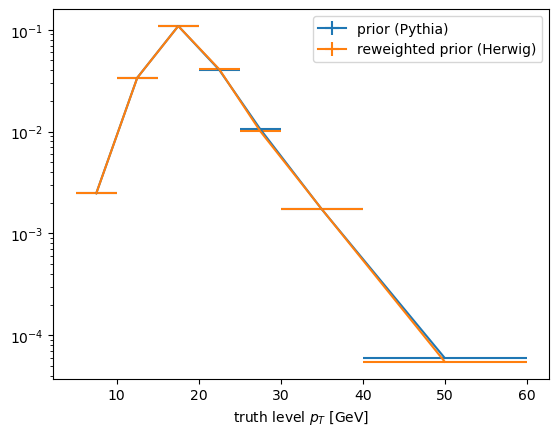

In [35]:
neff_array = []
for j in range(0, len(binedges)-1):
    neff = sum(df1[(df1[ob]>binedges[j]) & (df1[ob]<binedges[j+1])]['relw_new'])**2 / (1e-50+sum(df1[(df1[ob]>binedges[j]) & (df1[ob]<binedges[j+1])]['relw_new']**2))
    neff_array.append(neff)
print("reweighted MC effective counts:", neff_array)
plt.errorbar(x, y_old_prior, xerr=binedges[1:]-x, yerr=err_old_prior, label='prior (Pythia)')
plt.errorbar(x, y_prior, xerr=binedges[1:]-x, yerr=err_prior, label='reweighted prior (Herwig)')
plt.yscale('log')
plt.xlabel('truth level $p_T$ [GeV]')
plt.legend()

In [36]:
ob = 'pt'
binedges = np.array([20., 25., 30., 40., 60.])
x = []
for i in range(0, len(binedges)-1):
    midpoint = 0.5 * (binedges[i] + binedges[i+1])
    x.append(midpoint)

In [37]:
y_old_prior, err_old_prior = calc_hist_nonuniform(df1[ob], bins=binedges, weights=df1['w'], density=True)[:2]
y_prior, err_prior = calc_hist_nonuniform(df1[ob], bins=binedges, weights=df1['relw_new'], density=True)[:2]

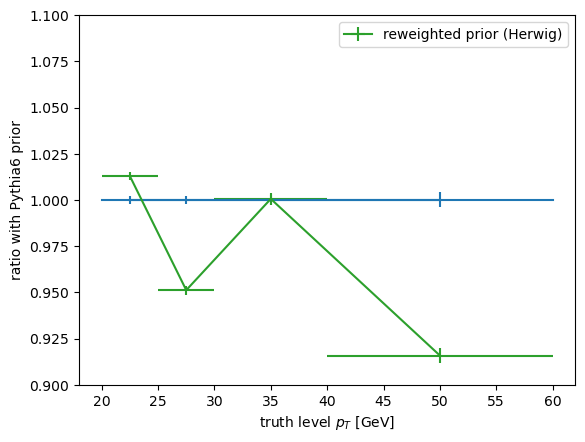

In [38]:
plt.errorbar(np.arange(20,61), np.ones(len(np.arange(20,61))))
plt.errorbar(x, np.ones(len(x)), yerr=err_old_prior/y_old_prior, color='tab:blue')
plt.errorbar(x, y_prior/y_old_prior*sum(y_old_prior)/sum(y_prior), xerr=binedges[1:]-x, yerr=err_prior/y_old_prior*sum(y_old_prior)/sum(y_prior), label='reweighted prior (Herwig)', color='tab:green')
plt.ylim(0.9,1.1)
plt.xlabel('truth level $p_T$ [GeV]')
plt.ylabel('ratio with Pythia6 prior')
plt.legend()

In [25]:
print(max(df1['relw_new']), min(df1[df1.relw_new>0]['relw_new']))

1.0 2.5733308110867956e-07


In [ ]:
df1.to_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_20235003.csv', index=False)

In [5]:
df1 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_20235003.csv', low_memory=False)